In [2]:
#import and configuration
import pydicom
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#load sample
dicom_path = pydicom.data.get_testdata_file("CT_small.dcm")

In [4]:
#read sample
ds = pydicom.dcmread(dicom_path)

In [9]:
print("Modality:", ds.Modality)
print("Patient ID:", ds.PatientID)
print("Rows:", ds.Rows)
print("Columns:", ds.Columns)
print("Pixel Spacing:", ds.PixelSpacing)
print("Image Position:", ds.ImagePositionPatient)

Modality: CT
Patient ID: 1CT1
Rows: 128
Columns: 128
Pixel Spacing: [0.661468, 0.661468]
Image Position: [-158.135803, -179.035797, -75.699997]


In [11]:
#extract pixel data
pixel_array = ds.pixel_array

print("Image shape:", pixel_array.shape)
print("Data type:", pixel_array.dtype)
print("Minimum pixel value:", pixel_array.min())
print("Maximum pixel value:", pixel_array.max())

Image shape: (128, 128)
Data type: int16
Minimum pixel value: 128
Maximum pixel value: 2191


In [12]:
#Convert to Hounsfield Units (HU)
slope = float(ds.RescaleSlope)
intercept = float(ds.RescaleIntercept)

hu_array = pixel_array * slope + intercept

print("HU minimum:", hu_array.min())
print("HU maximum:", hu_array.max())
print("HU data type:", hu_array.dtype)

HU minimum: -896.0
HU maximum: 1167.0
HU data type: float64


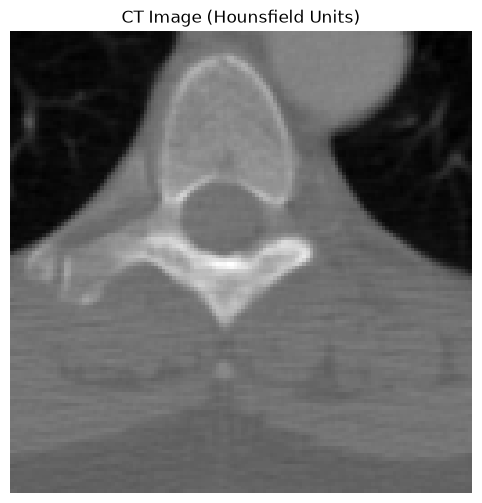

In [13]:
#visualize ct scan image 
plt.figure(figsize=(6, 6))
plt.imshow(hu_array, cmap="gray")
plt.title("CT Image (Hounsfield Units)")
plt.axis("off")
plt.show()

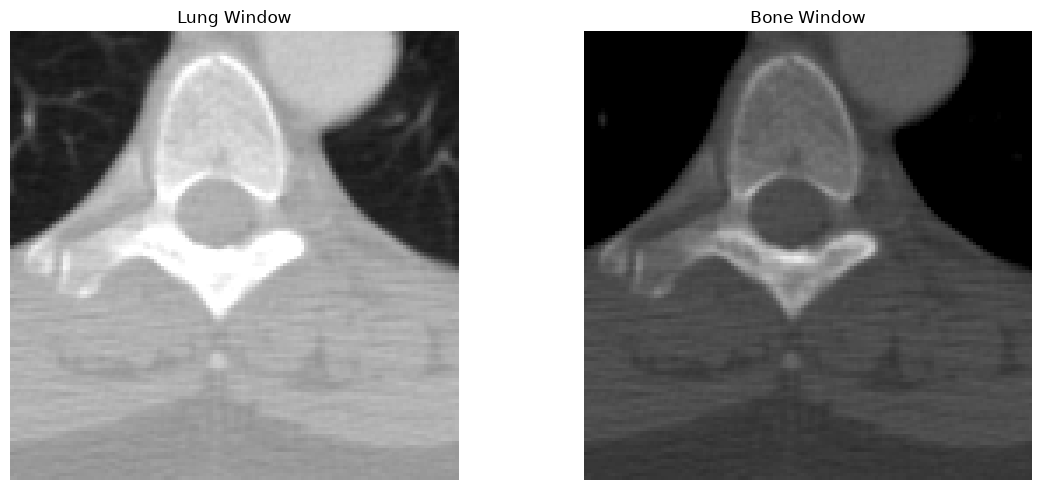

In [14]:
#CT scan windowing 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


axes[0].imshow(hu_array, cmap="gray", vmin=-1000, vmax=500)
axes[0].set_title("Lung Window")
axes[0].axis("off")


axes[1].imshow(hu_array, cmap="gray", vmin=-500, vmax=1300)
axes[1].set_title("Bone Window")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
#loading all the dicom slices 
from pathlib import Path

dicom_folder = Path("../data/dicom sample/ct-1mm")

print("Folder exists:", dicom_folder.exists())

dicom_files = list(dicom_folder.glob("*"))

print("Total files:", len(dicom_files))
print("First 5 files:")
for file in dicom_files[:5]:
    print(file.name)

Folder exists: True
Total files: 250
First 5 files:
001.dcm
002.dcm
003.dcm
004.dcm
005.dcm


In [7]:
#reconstructing the 3D volume


slices = [pydicom.dcmread(str(file)) for file in dicom_folder.glob("*.dcm")]


slices.sort(key=lambda ds: float(ds.ImagePositionPatient[2]))


volume = np.stack([
    ds.pixel_array.astype(np.float32) * float(ds.get("RescaleSlope", 1))
    + float(ds.get("RescaleIntercept", 0))
    for ds in slices
])


pixel_spacing = slices[0].PixelSpacing
z_positions = [float(ds.ImagePositionPatient[2]) for ds in slices]
slice_spacing = np.median(np.abs(np.diff(z_positions)))

voxel_spacing = (
    float(slice_spacing),
    float(pixel_spacing[0]),
    float(pixel_spacing[1])
)

print("3D Volume Shape:", volume.shape)
print("Voxel Spacing (mm):", voxel_spacing)
print("Volume Data Type:", volume.dtype)
print("HU Range:", volume.min(), "to", volume.max())


3D Volume Shape: (250, 512, 512)
Voxel Spacing (mm): (0.5, 0.40234375, 0.40234375)
Volume Data Type: float32
HU Range: -1024.0 to 1693.0


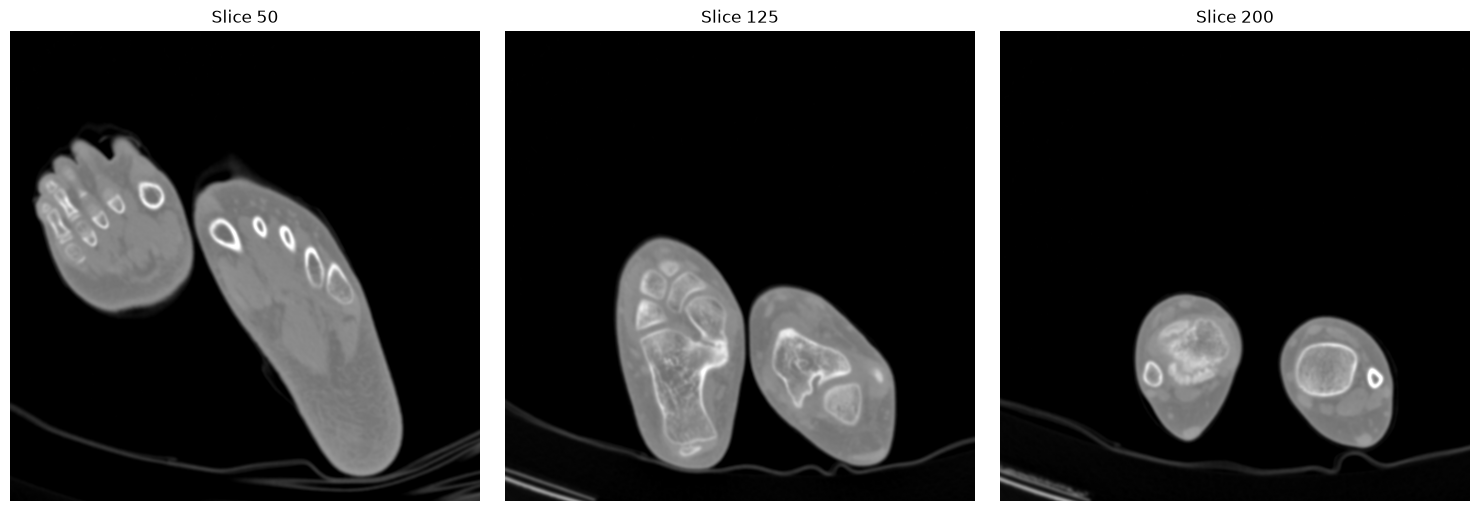

In [8]:
#visualize the 3D CT Volume 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

slice_indices = [50, 125, 200]

for ax, idx in zip(axes, slice_indices):
    ax.imshow(volume[idx], cmap="gray", vmin=-1000, vmax=1000)
    ax.set_title(f"Slice {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()